**09 - AUTO / ESCALATE Routing from Prediction-Interval Width** (code-only copy). Explanations: [`docs/notebooks/09_auto_escalate_routing.md`](../../docs/notebooks/09_auto_escalate_routing.md)

## Setup: imports, paths and data loading

In [1]:
import sys, json, warnings, io, unittest
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve()
while not (ROOT / 'CLAUDE.md').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.evaluation import routing as R, routing_runs as RR, segments as S, intervals as V, temporal as TP
from src.evaluation.run_feature_selection import load

pd.set_option('display.width', 230, 'display.max_columns', 45, 'display.max_rows', 150, 'display.max_colwidth', 80)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True); TAB = ROOT / 'reports' / 'tables'
RR.run_all()                                                         # no-op when cached
df, X, y, folds = load()
DEV = R.prepare(pd.read_csv(RR.OUT / 'dev_inner_oof.csv.gz'), 'cqr')
EV = R.prepare(pd.read_csv(RR.OUT / 'outer_eval.csv.gz'), 'cqr')
EV = S.add_segments(EV, df)
EV['price_pred'] = pd.cut(EV.point, [0, 130_000, 280_000, 1e12], right=False, labels=['low', 'mid', 'luxury'])
EV['flagged'] = EV.Id.isin([524, 1299])
TDEV = R.prepare(pd.read_csv(RR.OUT / 'temporal_dev_inner.csv.gz'), 'cqr'); TEV = pd.read_csv(RR.OUT / 'temporal_eval.csv.gz')
META = json.loads((RR.OUT / 'run_metadata.json').read_text())
GRID = list(R.GRID); P_ = R.SCENARIOS[R.PRIMARY]
print('development rows (inner out-of-fold, all outer folds):', len(DEV), '| outer-evaluation rows:', len(EV), '| houses:', EV.row.nunique(), '| experiment', META['experiment_id'])

development rows (inner out-of-fold, all outer folds): 17520 | outer-evaluation rows: 4380 | houses: 1460 | experiment routing_v1


## 3. The Routing Signal: Relative Interval Width

In [2]:
rr = pd.DataFrame({'development (inner OOF)': DEV.rel.describe(percentiles=[.1, .25, .5, .75, .9]), 'evaluation (outer OOF, all repeats)': EV.rel.describe(percentiles=[.1, .25, .5, .75, .9])})
display(rr.round(3))
raw_rel = R.relative_width(pd.read_csv(RR.OUT / 'outer_eval.csv.gz').lo_raw, pd.read_csv(RR.OUT / 'outer_eval.csv.gz').hi_raw, EV.point)
print('Spearman(relative width from CQR, from raw quantile intervals) = %.3f -> CQR preserves the ranking of properties by uncertainty' % stats.spearmanr(EV.rel, raw_rel)[0])
print('Interval width varies by property (not constant): coefficient of variation of USD width = %.2f; of relative width = %.2f' % ((EV.hi - EV.lo).std() / (EV.hi - EV.lo).mean(), EV.rel.std() / EV.rel.mean()))
print('Interval validity: all finite = %s; upper >= lower = %s; point predictions > 0 = %s' % (bool(np.isfinite(EV[['lo', 'hi', 'point']].values).all()), bool((EV.hi >= EV.lo).all()), bool((EV.point > 0).all())))
print('Which houses get wide intervals (CQR relative width, repeat 0), by deployable features:')
r0 = EV[EV.repeat == 0]
display(pd.concat({'predicted price': r0.groupby('price_pred', observed=True).rel.median(), 'quality tier': r0.groupby('quality_tier', observed=True).rel.median(), 'age group': r0.groupby('age_group', observed=True).rel.median(), 'living area': r0.groupby('area_group', observed=True).rel.median()}).round(3).to_frame('median relative width'))

,development (inner OOF),"evaluation (outer OOF, all repeats)"
count,17520.000,4380.000
mean,0.322,0.316
std,0.176,0.171
min,0.038,0.066
10%,0.161,0.160
25%,0.205,0.205
50%,0.274,0.270
75%,0.392,0.380
90%,0.538,0.525
max,1.936,1.839


Spearman(relative width from CQR, from raw quantile intervals) = 0.990 -> CQR preserves the ranking of properties by uncertainty
Interval width varies by property (not constant): coefficient of variation of USD width = 0.78; of relative width = 0.54
Interval validity: all finite = True; upper >= lower = True; point predictions > 0 = True
Which houses get wide intervals (CQR relative width, repeat 0), by deployable features:


median relative width
predicted price low                            0.362
                mid                            0.229
                luxury                         0.430
quality tier    low (1-4)                      0.475
                medium (5-8)                   0.245
                high (9-10)                    0.492
age group       <=10 yr                        0.245
                11-30 yr                       0.221
                31-60 yr                       0.247
                >60 yr                         0.377
living area     <=1,200 sq ft                  0.244
                1,201-1,800                    0.242
                >1,800 sq ft                   0.347

## 4. Development Threshold Comparison (the data on which thresholds are selected)

In [3]:
# For each outer fold: the development grid, the conservative bounds and the selected threshold of every scenario (development data only).
DEVTAB, TAU = {}, {s: {} for s in R.SCENARIOS}
for k, g in DEV.groupby('outer_fold'):
    boot = R.bootstrap_auto(g, GRID, R.N_BOOT, seed=R.SEED + k)
    for s, sc in R.SCENARIOS.items():
        tau, tab = R.select_threshold(g, sc, GRID, boot=boot); TAU[s][k] = tau
        if s == R.PRIMARY: DEVTAB[k] = tab
dtab = pd.concat(DEVTAB.values(), keys=DEVTAB.keys(), names=['fold', 'tau'])
agg = dtab.groupby('tau').agg(auto_share=('auto_share', 'mean'), auto_n=('auto_n', 'mean'), auto_mae=('auto_mae', 'mean'), auto_mape=('auto_mape', 'mean'), auto_mape_upper90=('auto_mape_upper90', 'mean'),
                              auto_coverage=('auto_coverage', 'mean'), escalate_share=('escalate_share', 'mean'), esc_mape=('esc_mape', 'mean'), folds_feasible=('feasible', 'sum'))
agg['selected as tau_k in N folds'] = pd.Series(TAU[R.PRIMARY]).value_counts().reindex(agg.index).fillna(0).astype(int)
display(agg.rename(columns={'auto_share': 'AUTO %', 'auto_n': 'AUTO N', 'auto_mae': 'AUTO MAE', 'auto_mape': 'AUTO MAPE', 'auto_mape_upper90': 'AUTO MAPE 90% upper', 'auto_coverage': 'AUTO coverage', 'escalate_share': 'ESCALATE %', 'esc_mape': 'ESCALATE MAPE'}).assign(**{'AUTO %': 100 * agg.auto_share, 'ESCALATE %': 100 * agg.escalate_share}).round({'AUTO %': 1, 'AUTO N': 0, 'AUTO MAE': 0, 'AUTO MAPE': 2, 'AUTO MAPE 90% upper': 2, 'AUTO coverage': 3, 'ESCALATE %': 1, 'ESCALATE MAPE': 2}))
print('Mean over the 15 development sets (each: 1,168 houses). "folds_feasible" = number of folds in which the threshold satisfies the primary scenario P (conservative AUTO MAPE <= 7% and AUTO N >= 100).')
tt = pd.DataFrame(TAU).rename_axis('outer fold')
tt = tt.replace(-np.inf, np.nan)
print('Thresholds selected per outer fold and scenario (NaN = nothing feasible: escalate everything):'); display(tt.T.round(3))
print('Summary of the selected thresholds:'); display(pd.DataFrame({s: dict(median=np.nanmedian(list(TAU[s].values())), min=np.nanmin(list(TAU[s].values())) if np.isfinite(list(TAU[s].values())).any() else np.nan, max=np.nanmax(list(TAU[s].values())) if np.isfinite(list(TAU[s].values())).any() else np.nan, folds_with_no_feasible_threshold=int(np.isneginf(list(TAU[s].values())).sum())) for s in R.SCENARIOS}).T.round(3))
agg.round(4).to_csv(TAB / 'routing_development_grid.csv'); tt.round(4).to_csv(TAB / 'routing_thresholds_by_fold.csv')

,AUTO %,AUTO N,AUTO MAE,AUTO MAPE,AUTO MAPE 90% upper,AUTO coverage,ESCALATE %,ESCALATE MAPE,folds_feasible,selected as tau_k in N folds
tau,,,,,,,,,,
0.160,9.7,113.0,8749.0,5.55,6.27,0.678,90.3,9.18,8,0
0.180,15.7,183.0,9105.0,5.71,6.31,0.714,84.3,9.41,14,1
0.200,23.0,269.0,9530.0,5.97,6.55,0.745,77.0,9.68,10,1
0.217,29.6,346.0,9896.0,6.13,6.64,0.758,70.4,9.97,12,0
0.220,30.8,360.0,9910.0,6.11,6.61,0.762,69.2,10.04,13,2
0.240,38.4,448.0,10246.0,6.27,6.74,0.777,61.6,10.42,10,2
0.260,45.4,530.0,10550.0,6.38,6.82,0.786,54.6,10.86,9,2
0.280,51.7,604.0,10875.0,6.51,6.92,0.790,48.3,11.31,7,2
0.300,56.9,665.0,11210.0,6.66,7.06,0.794,43.1,11.69,5,3


Mean over the 15 development sets (each: 1,168 houses). "folds_feasible" = number of folds in which the threshold satisfies the primary scenario P (conservative AUTO MAPE <= 7% and AUTO N >= 100).
Thresholds selected per outer fold and scenario (NaN = nothing feasible: escalate everything):


outer fold,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
P,0.22,0.32,0.30,0.34,0.24,0.28,0.24,0.20,0.22,0.28,0.30,0.30,0.26,0.26,0.18
S6,NaN,NaN,0.18,0.16,NaN,0.22,NaN,NaN,NaN,NaN,0.18,NaN,0.18,NaN,NaN
S8,0.38,0.40,0.54,0.56,0.46,0.50,0.34,0.42,0.50,0.46,0.48,0.44,0.40,0.42,0.38
S7pt,0.32,0.36,0.32,0.38,0.36,0.36,0.32,0.32,0.32,0.36,0.34,0.36,0.32,0.32,0.32
S7cov,NaN,NaN,NaN,0.34,NaN,0.26,NaN,NaN,NaN,NaN,0.30,0.30,NaN,NaN,NaN


Summary of the selected thresholds:


,median,min,max,folds_with_no_feasible_threshold
P,0.26,0.18,0.34,0.0
S6,-inf,-inf,0.22,10.0
S8,0.44,0.34,0.56,0.0
S7pt,0.32,0.32,0.38,0.0
S7cov,-inf,-inf,0.34,11.0


## 5. Independent Held-Out Evaluation of the Frozen Policy (nested)

In [4]:
def run_policy(taus):
    d = R.apply_frozen_thresholds(EV, taus); return d
POL = {s: run_policy(TAU[s]) for s in R.SCENARIOS}
rows = []
for s, d in POL.items():
    m = R.policy_metrics(d); rows.append({'scenario': R.SCENARIOS[s].name, 'median tau': np.nanmedian([t for t in TAU[s].values() if np.isfinite(t)]) if any(np.isfinite(list(TAU[s].values()))) else np.nan, 'AUTO %': 100 * m.auto_share, 'AUTO N (per repeat)': m.auto_n, 'AUTO MAE': m.auto_mae, 'AUTO RMSE': m.auto_rmse, 'AUTO MAPE': m.auto_mape, 'AUTO coverage': m.auto_coverage,
                                          'AUTO mean width': m.auto_mean_width, 'AUTO median rel. width': m.auto_median_rel_width, 'ESCALATE %': 100 * m.escalate_share, 'ESCALATE MAE': m.esc_mae, 'ESCALATE MAPE': m.esc_mape, 'ESCALATE coverage': m.esc_coverage, 'overall MAE': m.all_mae, 'overall MAPE': m.all_mape, 'overall coverage': m.all_coverage})
HELD = pd.DataFrame(rows).set_index('scenario')
display(HELD.round({'median tau': 3, 'AUTO %': 1, 'AUTO N (per repeat)': 0, 'AUTO MAE': 0, 'AUTO RMSE': 0, 'AUTO MAPE': 2, 'AUTO coverage': 3, 'AUTO mean width': 0, 'AUTO median rel. width': 3, 'ESCALATE %': 1, 'ESCALATE MAE': 0, 'ESCALATE MAPE': 2, 'ESCALATE coverage': 3, 'overall MAE': 0, 'overall MAPE': 2, 'overall coverage': 3}).T)
HELD.round(4).to_csv(TAB / 'routing_heldout_policy.csv')
print('Every number is computed within each CV repeat (every house once) and averaged over the 3 repeats. ESCALATE errors are those of the automated prediction before human review.')
P0 = POL[R.PRIMARY]; P00 = P0[P0.repeat == 0]
ci = R.bootstrap_policy(P00)
print('Primary scenario P, 95%% house-bootstrap intervals (repeat-0 routes, 1,460 houses): AUTO share %.3f-%.3f; AUTO MAPE %.2f-%.2f; AUTO MAE $%.0f-$%.0f; AUTO coverage %.3f-%.3f' % (*ci['auto_share'], *ci['auto_mape'], *ci['auto_mae'], *ci['auto_coverage']))
rep_rows = []
for r_, g_ in P0.groupby('repeat'):
    a_ = g_[g_.route == 'AUTO']; rep_rows.append({'CV repeat': r_, 'mean tau_k of its 5 folds': np.mean([TAU[R.PRIMARY][k] for k in g_.fold.unique()]), 'AUTO share': len(a_) / len(g_), 'AUTO N': len(a_), 'AUTO MAPE': 100 * a_.ape.mean(), 'AUTO coverage': a_.cover.mean()})
print('Primary policy by CV repeat (each repeat routes all 1,460 houses with its own 5 frozen fold thresholds): AUTO volume varies with the thresholds drawn, AUTO MAPE much less'); display(pd.DataFrame(rep_rows).set_index('CV repeat').round(3))
pd.DataFrame(rep_rows).round(4).to_csv(TAB / 'routing_primary_by_repeat.csv', index=False)
# optimism: development estimate at the chosen tau_k versus the held-out result in the same fold
rows = []
for k, tau in TAU[R.PRIMARY].items():
    ev_k = EV[EV.fold == k]; dv_k = DEV[DEV.outer_fold == k]
    if np.isfinite(tau):
        a_d, a_e = dv_k[dv_k.rel <= tau], ev_k[ev_k.rel <= tau]
        rows.append({'fold': k, 'tau_k': tau, 'dev AUTO MAPE': 100 * a_d.ape.mean(), 'held-out AUTO MAPE': 100 * a_e.ape.mean() if len(a_e) else np.nan, 'dev AUTO share': len(a_d) / len(dv_k), 'held-out AUTO share': len(a_e) / len(ev_k), 'dev AUTO coverage': a_d.cover.mean(), 'held-out AUTO coverage': a_e.cover.mean() if len(a_e) else np.nan})
OPT = pd.DataFrame(rows).set_index('fold')
print('Selection optimism for the primary scenario (15 folds): development estimate vs held-out result at the same tau_k'); display(OPT.mean().round(3).to_frame('mean over folds').join(OPT.std().round(3).to_frame('SD over folds')))
print('Folds in which the held-out AUTO MAPE exceeded the 7%% target: %d of %d' % ((OPT['held-out AUTO MAPE'] > 7).sum(), len(OPT)))

scenario,P: AUTO MAPE <= 7% (conservative),S6: AUTO MAPE <= 6% (conservative),S8: AUTO MAPE <= 8% (conservative),"S7pt: AUTO MAPE <= 7% (point estimate, non-conservative)",S7cov: P and AUTO coverage >= 80%
median tau,0.260,0.180,0.440,0.320,0.300
AUTO %,45.000,6.700,81.900,67.600,14.900
AUTO N (per repeat),658.000,98.000,1196.000,988.000,218.000
AUTO MAE,10821.000,10095.000,13157.000,11949.000,12132.000
AUTO RMSE,16468.000,13557.000,19683.000,18036.000,18034.000
AUTO MAPE,6.490,6.180,7.480,6.940,7.110
AUTO coverage,0.785,0.702,0.804,0.808,0.764
AUTO mean width,34274.000,25853.000,46551.000,40002.000,38029.000
AUTO median rel. width,0.201,0.158,0.244,0.225,0.220
ESCALATE %,55.000,93.300,18.100,32.400,85.100


Every number is computed within each CV repeat (every house once) and averaged over the 3 repeats. ESCALATE errors are those of the automated prediction before human review.
Primary scenario P, 95% house-bootstrap intervals (repeat-0 routes, 1,460 houses): AUTO share 0.503-0.550; AUTO MAPE 6.06-7.21; AUTO MAE $10519-$12241; AUTO coverage 0.744-0.805
Primary policy by CV repeat (each repeat routes all 1,460 houses with its own 5 frozen fold thresholds): AUTO volume varies with the thresholds drawn, AUTO MAPE much less


,mean tau_k of its 5 folds,AUTO share,AUTO N,AUTO MAPE,AUTO coverage
CV repeat,,,,,
0,0.284,0.527,770,6.600,0.774
1,0.244,0.379,553,6.358,0.772
2,0.260,0.445,650,6.522,0.808


Selection optimism for the primary scenario (15 folds): development estimate vs held-out result at the same tau_k


,mean over folds,SD over folds
tau_k,0.263,0.046
dev AUTO MAPE,6.394,0.232
held-out AUTO MAPE,6.262,1.010
dev AUTO share,0.451,0.155
held-out AUTO share,0.450,0.166
dev AUTO coverage,0.776,0.034
held-out AUTO coverage,0.784,0.035


Folds in which the held-out AUTO MAPE exceeded the 7% target: 4 of 15


## 6. Selection Stability and the Single Deployable Threshold

In [5]:
# Deployment development set: out-of-fold predictions of all 1,460 houses (CV repeat 0, one prediction per house). No untouched data remain,
# so the performance of this threshold is NOT independently measurable; the nested estimate of section 5 is the evidence for the procedure.
DEPLOY = EV[EV.repeat == 0].copy()
rows = {}
for s, sc in R.SCENARIOS.items():
    tau, tab = R.select_threshold(DEPLOY, sc, GRID, n_boot=1000, seed=R.SEED)
    rows[s] = {'scenario': sc.name, 'tau_final': tau, 'median of the 15 fold-wise tau_k': np.nanmedian([t for t in TAU[s].values() if np.isfinite(t)]) if any(np.isfinite(list(TAU[s].values()))) else np.nan}
DEP = pd.DataFrame(rows).T.set_index('scenario'); display(DEP)
DEP.to_csv(TAB / 'routing_deployment_thresholds.csv')
TAU_FINAL = float(rows[R.PRIMARY]['tau_final'])
_, tabF = R.select_threshold(DEPLOY, P_, GRID, n_boot=1000, seed=R.SEED)
print('Primary scenario, deployment development set (in-sample for this threshold, so optimistic): tau = %.2f -> AUTO %.1f%% (N = %d), AUTO MAPE %.2f%% (90%% upper bound %.2f%%), AUTO coverage %.3f' % (TAU_FINAL, 100 * tabF.loc[TAU_FINAL, 'auto_share'], tabF.loc[TAU_FINAL, 'auto_n'], tabF.loc[TAU_FINAL, 'auto_mape'], tabF.loc[TAU_FINAL, 'auto_mape_upper90'], tabF.loc[TAU_FINAL, 'auto_coverage']))
# stability: re-select on bootstrap resamples of the deployment development houses
rng = np.random.default_rng(7); sel = []
for b in range(100):
    g = DEPLOY.iloc[rng.integers(0, len(DEPLOY), len(DEPLOY))]
    sel.append(R.select_threshold(g, P_, GRID, n_boot=100, seed=b)[0])
sel = np.array(sel); fin = sel[np.isfinite(sel)]
pd.DataFrame([{'tau_final': TAU_FINAL, 'dev_auto_share': tabF.loc[TAU_FINAL, 'auto_share'], 'dev_auto_n': tabF.loc[TAU_FINAL, 'auto_n'], 'dev_auto_mape': tabF.loc[TAU_FINAL, 'auto_mape'], 'dev_auto_mape_upper90': tabF.loc[TAU_FINAL, 'auto_mape_upper90'], 'dev_auto_coverage': tabF.loc[TAU_FINAL, 'auto_coverage'], 'boot_tau_p10': np.percentile(fin, 10), 'boot_tau_p50': np.percentile(fin, 50), 'boot_tau_p90': np.percentile(fin, 90)}]).round(4).to_csv(TAB / 'routing_deployment_primary.csv', index=False)
print('Selection stability (100 bootstrap resamples of the houses): tau_final percentiles 10/50/90 = %s; share of resamples with nothing feasible = %.2f' % (np.round(np.percentile(fin, [10, 50, 90]), 3), np.isneginf(sel).mean()))
print('Neighbouring thresholds are not meaningfully different: AUTO MAPE bootstrap 95%% intervals around tau_final overlap heavily:')
bt = R.bootstrap_auto(DEPLOY, GRID, 1000, seed=3); gi = [GRID.index(TAU_FINAL) + o for o in (-2, -1, 0, 1, 2) if 0 <= GRID.index(TAU_FINAL) + o < len(GRID)]
display(pd.DataFrame({'tau': [GRID[i] for i in gi], 'AUTO %': [100 * tabF.iloc[i].auto_share for i in gi], 'AUTO MAPE': [tabF.iloc[i].auto_mape for i in gi], 'MAPE 95% lo': [np.nanpercentile(bt['mape'][:, i], 2.5) for i in gi], 'MAPE 95% hi': [np.nanpercentile(bt['mape'][:, i], 97.5) for i in gi]}).set_index('tau').round(2))

,tau_final,median of the 15 fold-wise tau_k
scenario,,
P: AUTO MAPE <= 7% (conservative),0.22,0.26
S6: AUTO MAPE <= 6% (conservative),-inf,0.18
S8: AUTO MAPE <= 8% (conservative),0.42,0.44
"S7pt: AUTO MAPE <= 7% (point estimate, non-conservative)",0.32,0.32
S7cov: P and AUTO coverage >= 80%,-inf,0.3


Primary scenario, deployment development set (in-sample for this threshold, so optimistic): tau = 0.22 -> AUTO 34.3% (N = 501), AUTO MAPE 6.02% (90% upper bound 6.38%), AUTO coverage 0.747


Selection stability (100 bootstrap resamples of the houses): tau_final percentiles 10/50/90 = [0.22 0.28 0.34]; share of resamples with nothing feasible = 0.00
Neighbouring thresholds are not meaningfully different: AUTO MAPE bootstrap 95%% intervals around tau_final overlap heavily:


,AUTO %,AUTO MAPE,MAPE 95% lo,MAPE 95% hi
tau,,,,
0.200,25.21,5.88,5.30,6.51
0.217,33.22,5.94,5.44,6.49
0.220,34.32,6.02,5.52,6.58
0.240,42.12,6.68,6.08,7.41
0.260,48.90,6.65,6.11,7.29


## 7. Automation versus Accuracy: Trade-off Curves

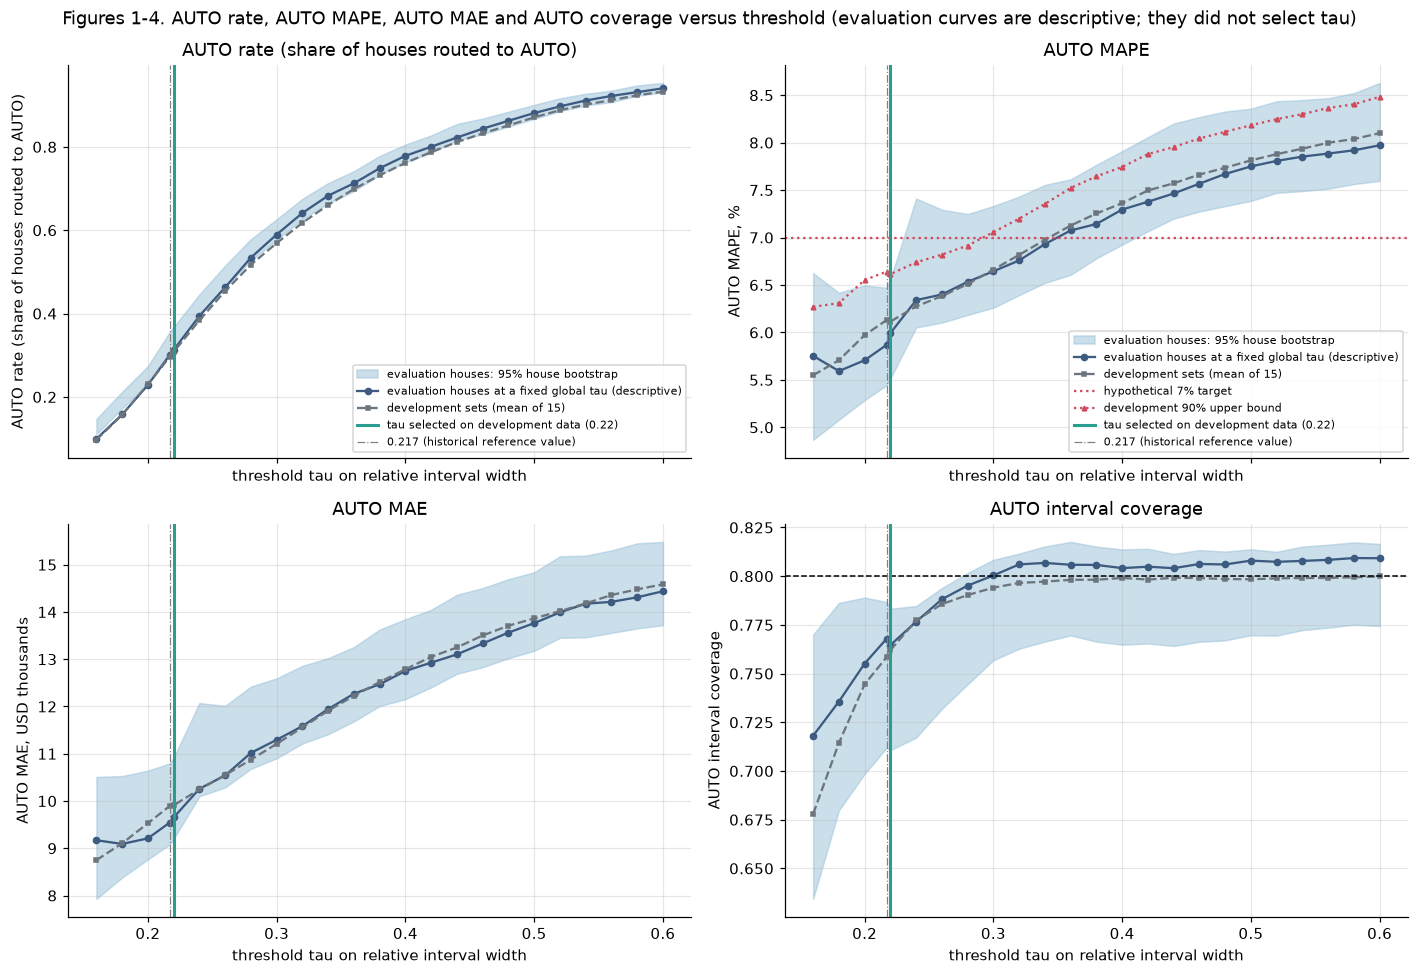

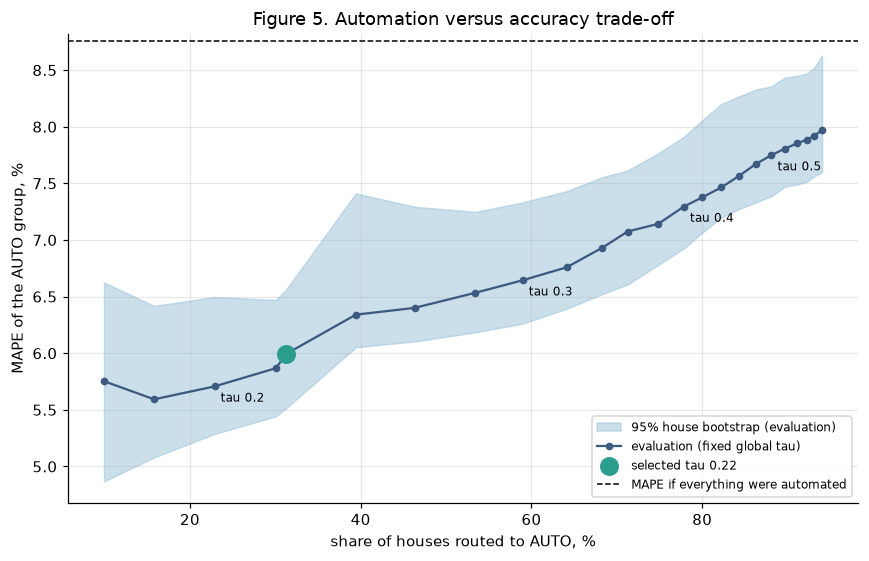

In [6]:
def eval_curve(d):
    per = [R.evaluate_grid(g, GRID) for _, g in d.groupby('repeat')]
    return sum(per) / len(per)
EC = eval_curve(EV)
bt0 = R.bootstrap_auto(EV[EV.repeat == 0], GRID, 1000, seed=11)
DC = agg
BIG = {'share': 'AUTO rate (share of houses routed to AUTO)', 'mape': 'AUTO MAPE, %', 'mae': 'AUTO MAE, USD thousands', 'coverage': 'AUTO interval coverage'}
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
for ax, key in zip(axes.ravel(), ['share', 'mape', 'mae', 'coverage']):
    ec = {'share': EC.auto_share, 'mape': EC.auto_mape, 'mae': EC.auto_mae / 1e3, 'coverage': EC.auto_coverage}[key]
    sc_ = 1e3 if key == 'mae' else 1
    lo, hi = np.nanpercentile(bt0[key], 2.5, axis=0) / sc_, np.nanpercentile(bt0[key], 97.5, axis=0) / sc_
    ax.fill_between(GRID, lo, hi, color='#98c1d9', alpha=.5, label='evaluation houses: 95% house bootstrap')
    ax.plot(GRID, ec, 'o-', color='#3d5a80', ms=4, label='evaluation houses at a fixed global tau (descriptive)')
    dv = {'share': DC.auto_share, 'mape': DC.auto_mape, 'mae': DC.auto_mae / 1e3, 'coverage': DC.auto_coverage}[key]
    ax.plot(GRID, dv, 's--', color='#6c757d', ms=3, label='development sets (mean of 15)')
    if key == 'mape': ax.axhline(7, color='#d1495b', ls=':', lw=1.5, label='hypothetical 7% target'); ax.plot(GRID, DC.auto_mape_upper90, '^:', color='#d1495b', ms=3, label='development 90% upper bound')
    if key == 'coverage': ax.axhline(.8, color='k', ls='--', lw=1, label='nominal 80%')
    ax.axvline(TAU_FINAL, color='#2a9d8f', lw=2, label=f'tau selected on development data ({TAU_FINAL:.2f})'); ax.axvline(0.217, color='grey', lw=.8, ls='-.', label='0.217 (historical reference value)')
    ax.set_ylabel(BIG[key]); ax.set_xlabel('threshold tau on relative interval width'); ax.set_title(BIG[key].split(',')[0])
axes[0, 0].legend(fontsize=7, loc='lower right'); axes[0, 1].legend(fontsize=7, loc='lower right')
fig.suptitle('Figures 1-4. AUTO rate, AUTO MAPE, AUTO MAE and AUTO coverage versus threshold (evaluation curves are descriptive; they did not select tau)'); plt.tight_layout(); plt.savefig(FIG / 'routing_fig1_4_curves.png'); plt.show()
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.fill_between(100 * EC.auto_share, np.nanpercentile(bt0['mape'], 2.5, axis=0), np.nanpercentile(bt0['mape'], 97.5, axis=0), color='#98c1d9', alpha=.5, label='95% house bootstrap (evaluation)')
ax.plot(100 * EC.auto_share, EC.auto_mape, 'o-', color='#3d5a80', ms=4, label='evaluation (fixed global tau)')
for t in (0.2, 0.3, 0.4, 0.5):
    ax.annotate(f'tau {t}', (100 * EC.loc[t, 'auto_share'], EC.loc[t, 'auto_mape']), fontsize=8, xytext=(4, -10), textcoords='offset points')
ax.scatter([100 * EC.loc[TAU_FINAL, 'auto_share']], [EC.loc[TAU_FINAL, 'auto_mape']], s=130, color='#2a9d8f', zorder=4, label=f'selected tau {TAU_FINAL:.2f}')
ax.axhline(EV.ape.mean() * 100, color='k', ls='--', lw=1, label='MAPE if everything were automated')
ax.set_xlabel('share of houses routed to AUTO, %'); ax.set_ylabel('MAPE of the AUTO group, %'); ax.set_title('Figure 5. Automation versus accuracy trade-off'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'routing_fig5_tradeoff.png'); plt.show()

### 7.2 Chart: relative-width distribution and the chosen threshold

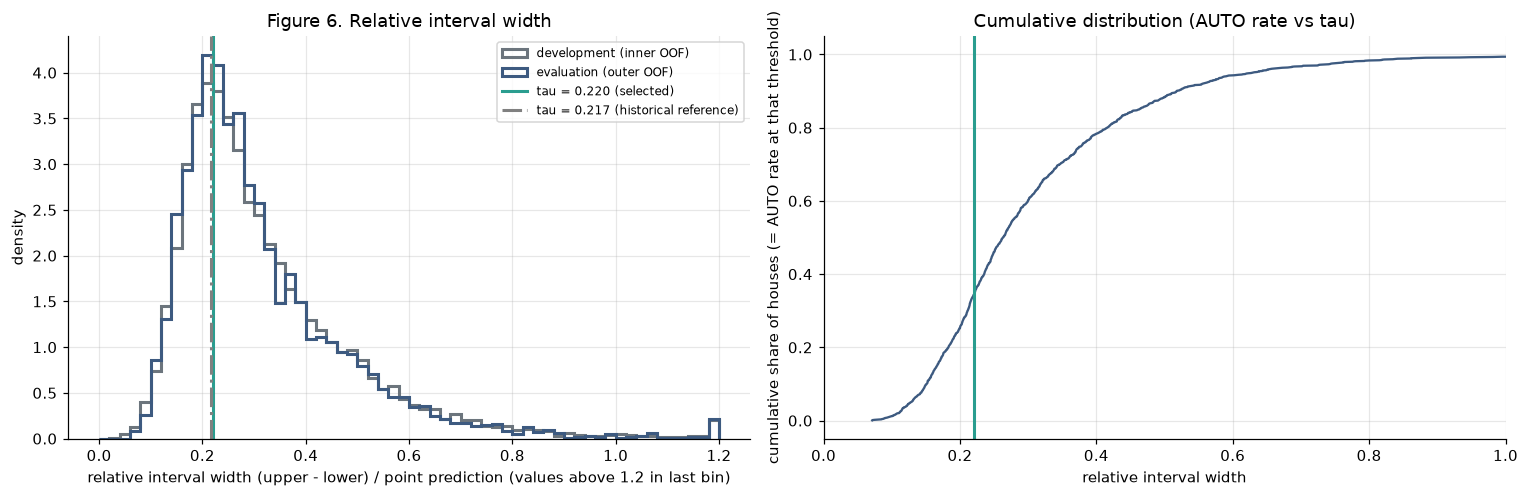

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
bins = np.linspace(0, 1.2, 61)
axes[0].hist(np.clip(DEV.rel, 0, 1.2), bins=bins, density=True, histtype='step', lw=2, color='#6c757d', label='development (inner OOF)'); axes[0].hist(np.clip(EV.rel, 0, 1.2), bins=bins, density=True, histtype='step', lw=2, color='#3d5a80', label='evaluation (outer OOF)')
for t, col in [(TAU_FINAL, '#2a9d8f'), (0.217, 'grey')]: axes[0].axvline(t, color=col, lw=2, ls='-' if t == TAU_FINAL else '-.', label=f'tau = {t:.3f}' + (' (selected)' if t == TAU_FINAL else ' (historical reference)'))
axes[0].set_xlabel('relative interval width (upper - lower) / point prediction (values above 1.2 in last bin)'); axes[0].set_ylabel('density'); axes[0].set_title('Figure 6. Relative interval width'); axes[0].legend(fontsize=8)
P0 = POL[R.PRIMARY]; P00 = P0[P0.repeat == 0]
cum = EV[EV.repeat == 0].sort_values('rel'); axes[1].plot(cum.rel, np.arange(1, len(cum) + 1) / len(cum), color='#3d5a80'); axes[1].axvline(TAU_FINAL, color='#2a9d8f', lw=2); axes[1].set_xlim(0, 1.0)
axes[1].set_xlabel('relative interval width'); axes[1].set_ylabel('cumulative share of houses (= AUTO rate at that threshold)'); axes[1].set_title('Cumulative distribution (AUTO rate vs tau)')
plt.tight_layout(); plt.savefig(FIG / 'routing_fig6_width.png'); plt.show()

## 8. Coverage and Error: AUTO versus ESCALATE (frozen primary policy, held-out)

,n,MAE,median_AE,p90_AE,MAPE,median_APE,p90_APE,p95_APE,coverage,share_APE_over_15pct,mean_width,median_rel_width,signed_error
AUTO,658.0,10873.0,7557.0,23838.0,6.51,4.55,12.94,16.99,0.785,0.070,34405.0,0.200,96.0
ESCALATE,802.0,19356.0,12126.0,39469.0,10.60,7.57,21.01,28.00,0.826,0.203,74980.0,0.367,2795.0


AUTO: coverage 0.774, 95% Wilson interval (houses, repeat 0) 0.743-0.802, one-sided binomial p (< 80%) = 0.0410
ESCALATE: coverage 0.822, 95% Wilson interval (houses, repeat 0) 0.791-0.848, one-sided binomial p (< 80%) = 0.9315
Rank correlation, held-out: relative width vs |percentage error| = 0.293; vs absolute USD error = 0.254


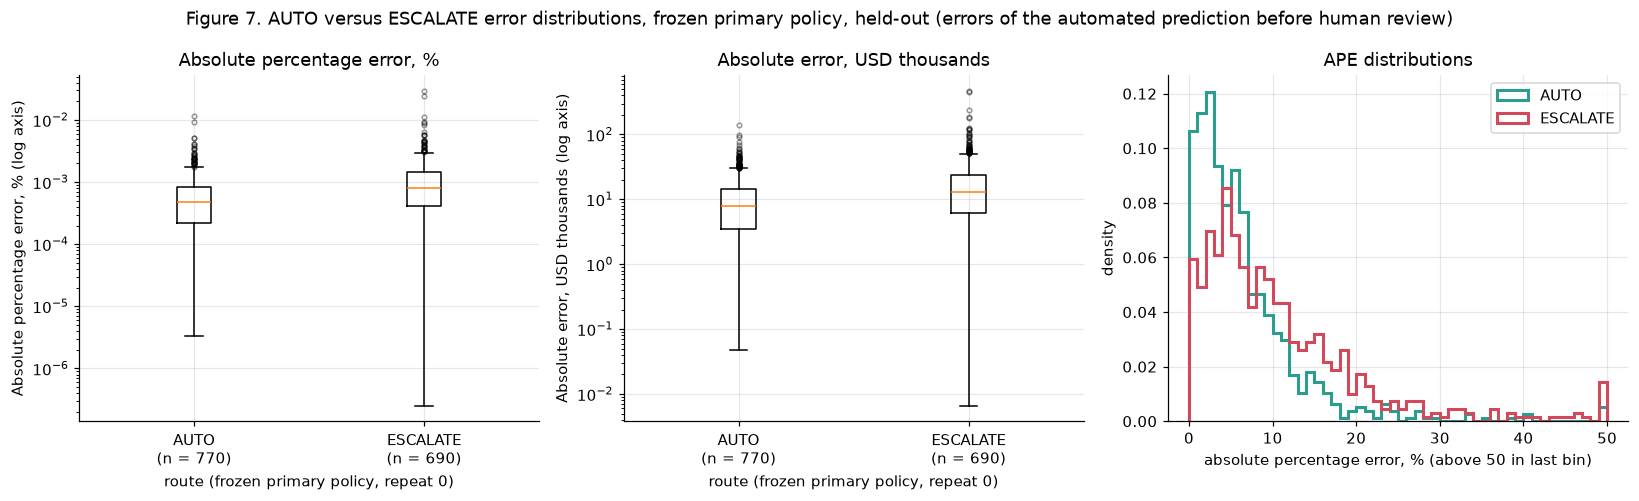

In [8]:
g = P0.copy(); g['abs_err'] = (g.y - g.point).abs()
def rtab(d):
    rows = {}
    for r_ in ['AUTO', 'ESCALATE']:
        x = d[d.route == r_]
        rows[r_] = dict(n=len(x) / d.repeat.nunique(), MAE=x.abs_err.mean(), median_AE=x.abs_err.median(), p90_AE=x.abs_err.quantile(.9), MAPE=100 * x.ape.mean(), median_APE=100 * x.ape.median(), p90_APE=100 * x.ape.quantile(.9), p95_APE=100 * x.ape.quantile(.95), coverage=x.cover.mean(),
                        share_APE_over_15pct=(x.ape > .15).mean(), mean_width=(x.hi - x.lo).mean(), median_rel_width=x.rel.median(), signed_error=(x.y - x.point).mean())
    return pd.DataFrame(rows).T
display(rtab(g).round({'n': 0, 'MAE': 0, 'median_AE': 0, 'p90_AE': 0, 'MAPE': 2, 'median_APE': 2, 'p90_APE': 2, 'p95_APE': 2, 'coverage': 3, 'share_APE_over_15pct': 3, 'mean_width': 0, 'median_rel_width': 3, 'signed_error': 0}))
rtab(g).round(5).to_csv(TAB / 'routing_primary_group_errors.csv')
c0 = P00.groupby('route').cover.agg(['sum', 'count'])
for r_ in c0.index:
    lo, hi = R.wilson(int(c0.loc[r_, 'sum']), int(c0.loc[r_, 'count'])); print(f'{r_}: coverage {c0.loc[r_, "sum"] / c0.loc[r_, "count"]:.3f}, 95% Wilson interval (houses, repeat 0) {lo:.3f}-{hi:.3f}, one-sided binomial p (< 80%) = {stats.binomtest(int(c0.loc[r_, "sum"]), int(c0.loc[r_, "count"]), .8, alternative="less").pvalue:.4f}')
print('Rank correlation, held-out: relative width vs |percentage error| = %.3f; vs absolute USD error = %.3f' % (stats.spearmanr(P00.rel, P00.ape)[0], stats.spearmanr(P00.rel, (P00.y - P00.point).abs())[0]))
pd.DataFrame([{'spearman_width_vs_ape': stats.spearmanr(P00.rel, P00.ape)[0], 'spearman_width_vs_abs_usd_error': stats.spearmanr(P00.rel, (P00.y - P00.point).abs())[0], 'n_houses': len(P00)}]).round(5).to_csv(TAB / 'routing_signal_strength.csv', index=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, col, ttl, sc_ in [(axes[0], 'ape', 'Absolute percentage error, %', 100), (axes[1], 'abs_err', 'Absolute error, USD thousands', 1e3)]:
    data = [P00[P00.route == r_].assign(abs_err=lambda d: (d.y - d.point).abs())[col] / sc_ for r_ in ['AUTO', 'ESCALATE']]
    ax.boxplot(data, showfliers=True, flierprops=dict(markersize=3, alpha=.4)); ax.set_yscale('log'); ax.set_xticks([1, 2]); ax.set_xticklabels([f'AUTO\n(n = {len(data[0])})', f'ESCALATE\n(n = {len(data[1])})']); ax.set_ylabel(ttl + ' (log axis)'); ax.set_xlabel('route (frozen primary policy, repeat 0)'); ax.set_title(ttl)
for r_, col in [('AUTO', '#2a9d8f'), ('ESCALATE', '#d1495b')]: axes[2].hist(100 * P00[P00.route == r_].ape.clip(upper=.5), bins=np.linspace(0, 50, 51), density=True, histtype='step', lw=2, color=col, label=r_)
axes[2].set_xlabel('absolute percentage error, % (above 50 in last bin)'); axes[2].set_ylabel('density'); axes[2].set_title('APE distributions'); axes[2].legend()
fig.suptitle('Figure 7. AUTO versus ESCALATE error distributions, frozen primary policy, held-out (errors of the automated prediction before human review)'); plt.tight_layout(); plt.savefig(FIG / 'routing_fig7_error_distributions.png'); plt.show()

## 9. Segment Routing Diagnostics (frozen primary policy, held-out)

In [9]:
SEG = {}
for lab, by in [('Predicted-price band', 'price_pred'), ('OverallQual tier', 'quality_tier'), ('Age group', 'age_group'), ('Living-area group', 'area_group'), ('Neighbourhood (n >= 30)', 'Neighborhood')]:
    t = R.segment_routing(P0, by, min_n=30 if by == 'Neighborhood' else 0); SEG[by] = t
    print(lab); display((t.assign(**{'AUTO %': 100 * t.auto_share, 'ESCALATE %': 100 * t.escalate_share})[['n', 'AUTO %', 'auto_n', 'auto_mae', 'auto_mape', 'auto_coverage', 'ESCALATE %', 'auto_share_lo', 'auto_share_hi']]).round({'n': 0, 'AUTO %': 1, 'auto_n': 0, 'auto_mae': 0, 'auto_mape': 2, 'auto_coverage': 3, 'ESCALATE %': 1, 'auto_share_lo': 3, 'auto_share_hi': 3}).sort_values('AUTO %'))
    t.round(4).to_csv(TAB / f'routing_segments_{by}.csv')
ov = P0.groupby('repeat').apply(lambda g: (g.route == 'AUTO').mean(), include_groups=False).mean()
print('Overall AUTO share %.3f. Groups whose AUTO share (Wilson 95%% interval) lies entirely below / above the overall share:' % ov)
for by in SEG:
    t = SEG[by]; lo_ = t[t.auto_share_hi < ov].index.tolist(); hi_ = t[t.auto_share_lo > ov].index.tolist(); print(f'  {by}: below {lo_} | above {hi_}')

Predicted-price band


,n,AUTO %,auto_n,auto_mae,auto_mape,auto_coverage,ESCALATE %,auto_share_lo,auto_share_hi
price_pred,,,,,,,,,
luxury,142.0,7.3,10.0,33858.0,12.86,0.649,92.7,0.061,0.162
low,371.0,26.2,97.0,7907.0,7.36,0.760,73.8,0.258,0.351
mid,947.0,58.0,550.0,10888.0,6.21,0.791,42.0,0.646,0.705


OverallQual tier


,n,AUTO %,auto_n,auto_mae,auto_mape,auto_coverage,ESCALATE %,auto_share_lo,auto_share_hi
quality_tier,,,,,,,,,
high (9-10),61.0,1.1,1.0,13896.0,5.12,1.000,98.9,0.000,0.059
low (1-4),141.0,12.3,17.0,8631.0,6.76,0.788,87.7,0.105,0.225
medium (5-8),1258.0,50.8,640.0,10872.0,6.49,0.784,49.2,0.567,0.621


Age group


...

Living-area group


,n,AUTO %,auto_n,auto_mae,auto_mape,auto_coverage,ESCALATE %,auto_share_lo,auto_share_hi
area_group,,,,,,,,,
">1,800 sq ft",340.0,21.8,74.0,16635.0,6.98,0.755,78.2,0.270,0.369
"<=1,200 sq ft",435.0,50.7,221.0,7345.0,5.87,0.823,49.3,0.516,0.609
"1,201-1,800",685.0,53.0,363.0,11770.0,6.77,0.766,47.0,0.572,0.645


Neighbourhood (n >= 30)


,n,AUTO %,auto_n,auto_mae,auto_mape,auto_coverage,ESCALATE %,auto_share_lo,auto_share_hi
Neighborhood,,,,,,,,,
IDOTRR,37.0,11.7,4.0,7594.0,6.04,0.875,88.3,0.114,0.372
Crawfor,51.0,15.0,8.0,29033.0,16.51,0.690,85.0,0.171,0.409
NoRidge,41.0,19.5,8.0,24070.0,8.96,0.413,80.5,0.176,0.445
NridgHt,77.0,22.9,18.0,14240.0,6.19,0.795,77.1,0.186,0.381
OldTown,113.0,24.8,28.0,7972.0,7.14,0.742,75.2,0.240,0.409
Edwards,100.0,25.0,25.0,12131.0,9.32,0.610,75.0,0.219,0.396
BrkSide,58.0,33.3,19.0,10966.0,7.88,0.726,66.7,0.251,0.491
Timber,38.0,38.6,15.0,17225.0,7.93,0.652,61.4,0.301,0.603
Mitchel,49.0,49.0,24.0,9353.0,6.30,0.818,51.0,0.452,0.718


Overall AUTO share 0.450. Groups whose AUTO share (Wilson 95% interval) lies entirely below / above the overall share:
  price_pred: below ['low', 'luxury'] | above ['mid']
  quality_tier: below ['high (9-10)', 'low (1-4)'] | above ['medium (5-8)']
  age_group: below ['>60 yr'] | above ['11-30 yr', '31-60 yr', '<=10 yr']
  area_group: below ['>1,800 sq ft'] | above ['1,201-1,800', '<=1,200 sq ft']
  Neighborhood: below ['Crawfor', 'Edwards', 'IDOTRR', 'NoRidge', 'NridgHt', 'OldTown'] | above ['CollgCr', 'Gilbert', 'Mitchel', 'NAmes', 'NWAmes', 'Sawyer', 'SawyerW', 'Somerst']


### 9.2 Chart: AUTO share by neighbourhood

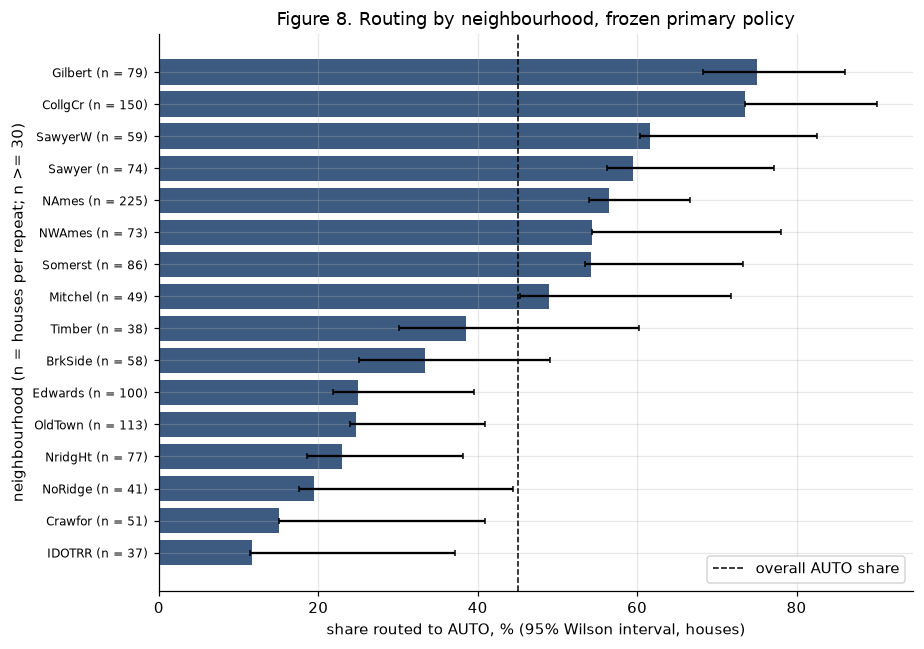

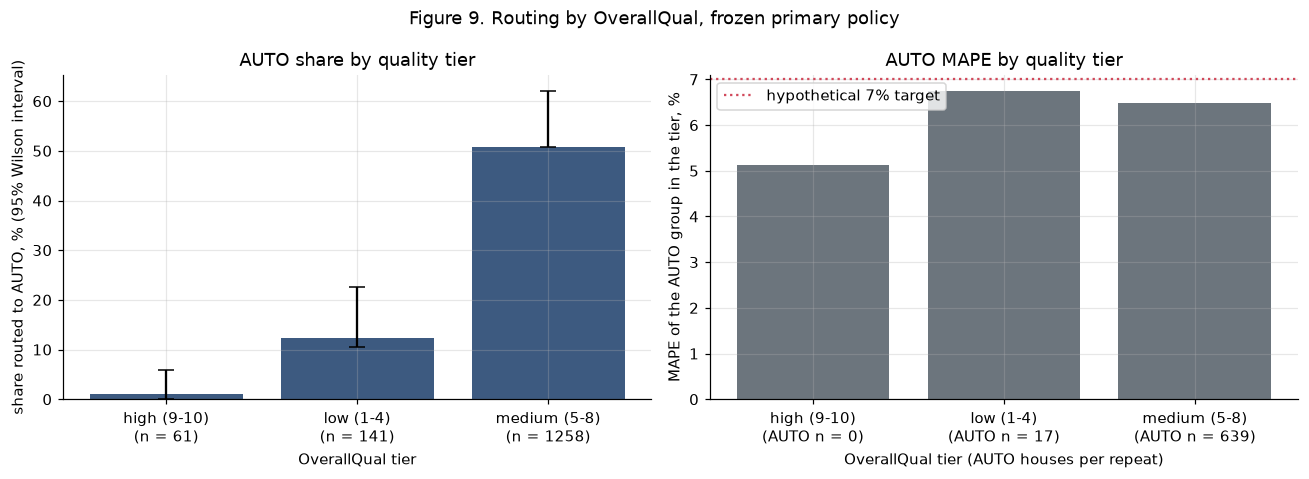

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 6))
t = SEG['Neighborhood'].sort_values('auto_share')
ax.barh(range(len(t)), 100 * t.auto_share, xerr=[100 * (t.auto_share - t.auto_share_lo).clip(lower=0), 100 * (t.auto_share_hi - t.auto_share).clip(lower=0)], color='#3d5a80', capsize=2)
ax.axvline(100 * ov, color='k', ls='--', lw=1, label='overall AUTO share'); ax.set_yticks(range(len(t))); ax.set_yticklabels([f'{i} (n = {int(n)})' for i, n in zip(t.index, t.n)], fontsize=8)
ax.set_xlabel('share routed to AUTO, % (95% Wilson interval, houses)'); ax.set_ylabel('neighbourhood (n = houses per repeat; n >= 30)'); ax.set_title('Figure 8. Routing by neighbourhood, frozen primary policy'); ax.legend()
plt.tight_layout(); plt.savefig(FIG / 'routing_fig8_neighborhood.png'); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
t = SEG['quality_tier']
axes[0].bar(range(len(t)), 100 * t.auto_share, yerr=[100 * (t.auto_share - t.auto_share_lo).clip(lower=0), 100 * (t.auto_share_hi - t.auto_share).clip(lower=0)], color='#3d5a80', capsize=5); axes[0].set_xticks(range(len(t))); axes[0].set_xticklabels([f'{i}\n(n = {int(n)})' for i, n in zip(t.index, t.n)]); axes[0].set_ylabel('share routed to AUTO, % (95% Wilson interval)'); axes[0].set_xlabel('OverallQual tier'); axes[0].set_title('AUTO share by quality tier')
axes[1].bar(range(len(t)), t.auto_mape, color='#6c757d'); axes[1].axhline(7, color='#d1495b', ls=':', label='hypothetical 7% target'); axes[1].set_xticks(range(len(t))); axes[1].set_xticklabels([f'{i}\n(AUTO n = {int(a)})' for i, a in zip(t.index, t.auto_n)]); axes[1].set_ylabel('MAPE of the AUTO group in the tier, %'); axes[1].set_xlabel('OverallQual tier (AUTO houses per repeat)'); axes[1].set_title('AUTO MAPE by quality tier'); axes[1].legend()
fig.suptitle('Figure 9. Routing by OverallQual, frozen primary policy'); plt.tight_layout(); plt.savefig(FIG / 'routing_fig9_quality.png'); plt.show()

## 10. Temporal Routing Robustness (train 2006-2008, test 2009-2010)

Thresholds selected on the 947 training-year houses: {'P': 0.32, 'S6': 0.24, 'S8': 0.58, 'S7pt': 0.38, 'S7cov': 'none feasible'}
Frozen temporal policy (first calibration split) and variability over 10 calibration splits:


,tau_T,AUTO % (mean),AUTO % (min),AUTO % (max),AUTO MAE (mean),AUTO MAPE (mean),AUTO MAPE (min),AUTO MAPE (max),AUTO coverage (mean),ESCALATE % (mean),ESCALATE MAPE (mean)
scenario,,,,,,,,,,,
P,0.32,64.522,59.454,67.836,12618.074,8.156,7.951,8.378,0.755,35.478,12.437
S6,0.24,43.450,33.918,52.827,11647.837,8.022,7.577,8.406,0.741,56.550,10.972
S8,0.58,93.041,91.423,94.347,15499.603,9.120,8.955,9.256,0.768,6.959,17.105
S7pt,0.38,74.971,71.150,77.193,13402.948,8.483,8.254,8.635,0.760,25.029,13.263
S7cov,-inf,0.000,0.000,0.000,NaN,NaN,NaN,NaN,NaN,100.000,9.673


For comparison, nested random-CV held-out results (section 5):


,AUTO %,AUTO MAE,AUTO MAPE,AUTO coverage,ESCALATE %,ESCALATE MAPE
scenario,,,,,,
P: AUTO MAPE <= 7% (conservative),45.046,10820.802,6.493,0.785,54.954,10.660
S6: AUTO MAPE <= 6% (conservative),6.735,10095.125,6.183,0.702,93.265,8.946
S8: AUTO MAPE <= 8% (conservative),81.918,13156.731,7.477,0.804,18.082,14.600
"S7pt: AUTO MAPE <= 7% (point estimate, non-conservative)",67.648,11949.120,6.944,0.808,32.352,12.573
S7cov: P and AUTO coverage >= 80%,14.909,12132.480,7.108,0.764,85.091,9.069


Primary scenario: development estimate at tau_T: AUTO 65.2%, AUTO MAPE 6.61%, AUTO coverage 0.783 (development houses: 947)
Primary policy by test year (first calibration split):


,n,AUTO %,AUTO MAPE,AUTO coverage,overall MAPE,overall coverage
YrSold,,,,,,
2009,338.0,66.272,8.152,0.741,10.052,0.754
2010,175.0,68.571,8.248,0.783,8.942,0.777


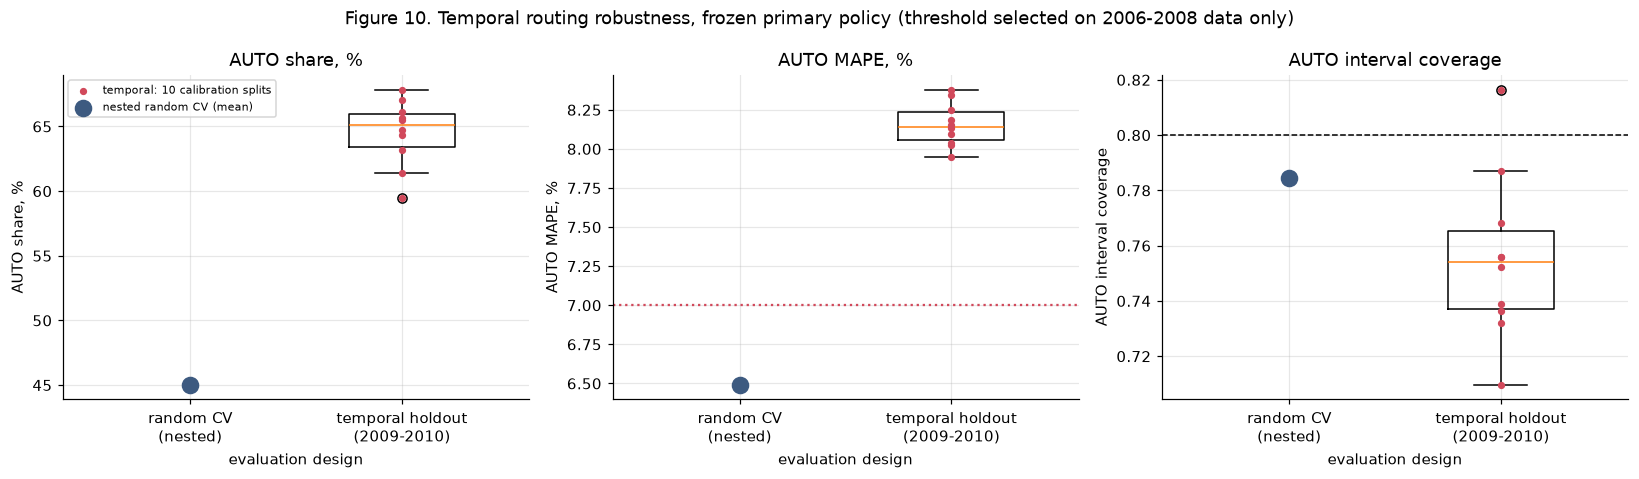

In [11]:
TT = {}
for s, sc in R.SCENARIOS.items():
    TT[s] = R.select_threshold(TDEV, sc, GRID, n_boot=1000, seed=R.SEED)[0]
print('Thresholds selected on the 947 training-year houses:', {s: (round(t, 3) if np.isfinite(t) else 'none feasible') for s, t in TT.items()})
rows = []
for s in R.SCENARIOS:
    tau = TT[s]
    for seed, g in TEV.groupby('seed'):
        d = R.prepare(g, 'cqr'); d['route'] = R.assign_route(d.rel.values, tau)
        a, e = d[d.route == 'AUTO'], d[d.route == 'ESCALATE']
        rows.append({'scenario': s, 'seed': seed, 'tau_T': tau, 'AUTO %': 100 * len(a) / len(d), 'AUTO N': len(a), 'AUTO MAE': (a.y - a.point).abs().mean(), 'AUTO MAPE': 100 * a.ape.mean(), 'AUTO coverage': a.cover.mean(), 'ESCALATE %': 100 * len(e) / len(d), 'ESCALATE MAPE': 100 * e.ape.mean(), 'ESCALATE coverage': e.cover.mean()})
TR = pd.DataFrame(rows)
first = TR[TR.seed == TR.seed.min()].set_index('scenario')
print('Frozen temporal policy (first calibration split) and variability over 10 calibration splits:')
summ = TR.groupby('scenario').agg(**{'tau_T': ('tau_T', 'first'), 'AUTO % (mean)': ('AUTO %', 'mean'), 'AUTO % (min)': ('AUTO %', 'min'), 'AUTO % (max)': ('AUTO %', 'max'), 'AUTO MAE (mean)': ('AUTO MAE', 'mean'), 'AUTO MAPE (mean)': ('AUTO MAPE', 'mean'), 'AUTO MAPE (min)': ('AUTO MAPE', 'min'), 'AUTO MAPE (max)': ('AUTO MAPE', 'max'), 'AUTO coverage (mean)': ('AUTO coverage', 'mean'), 'ESCALATE % (mean)': ('ESCALATE %', 'mean'), 'ESCALATE MAPE (mean)': ('ESCALATE MAPE', 'mean')}).loc[list(R.SCENARIOS)]
display(summ.round(3)); summ.round(4).to_csv(TAB / 'routing_temporal.csv')
rnd = HELD[['AUTO %', 'AUTO MAE', 'AUTO MAPE', 'AUTO coverage', 'ESCALATE %', 'ESCALATE MAPE']]
print('For comparison, nested random-CV held-out results (section 5):'); display(rnd.round(3))
dvT = TDEV[TDEV.rel <= TT[R.PRIMARY]] if np.isfinite(TT[R.PRIMARY]) else TDEV.iloc[:0]
print('Primary scenario: development estimate at tau_T: AUTO %.1f%%, AUTO MAPE %.2f%%, AUTO coverage %.3f (development houses: 947)' % (100 * len(dvT) / len(TDEV), 100 * dvT.ape.mean(), dvT.cover.mean()))
g1 = R.prepare(TEV[TEV.seed == TEV.seed.min()], 'cqr'); g1['route'] = R.assign_route(g1.rel.values, TT[R.PRIMARY])
print('Primary policy by test year (first calibration split):'); display(g1.groupby('YrSold').apply(lambda g: pd.Series({'n': len(g), 'AUTO %': 100 * (g.route == 'AUTO').mean(), 'AUTO MAPE': 100 * g[g.route == 'AUTO'].ape.mean(), 'AUTO coverage': g[g.route == 'AUTO'].cover.mean(), 'overall MAPE': 100 * g.ape.mean(), 'overall coverage': g.cover.mean()}), include_groups=False).round(3))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, key, ttl in [(axes[0], 'AUTO %', 'AUTO share, %'), (axes[1], 'AUTO MAPE', 'AUTO MAPE, %'), (axes[2], 'AUTO coverage', 'AUTO interval coverage')]:
    sub = TR[TR.scenario == R.PRIMARY]; ax.boxplot([sub[key]], positions=[2], widths=.5); ax.scatter([2] * len(sub), sub[key], color='#d1495b', s=14, zorder=3, label='temporal: 10 calibration splits')
    if key == 'AUTO %': ax.scatter([1], [HELD.loc[R.SCENARIOS[R.PRIMARY].name, key]], s=110, color='#3d5a80', zorder=3, label='nested random CV (mean)')
    elif key == 'AUTO MAPE': ax.scatter([1], [HELD.loc[R.SCENARIOS[R.PRIMARY].name, key]], s=110, color='#3d5a80', zorder=3); ax.axhline(7, color='#d1495b', ls=':', label='hypothetical 7% target')
    else: ax.scatter([1], [HELD.loc[R.SCENARIOS[R.PRIMARY].name, key]], s=110, color='#3d5a80', zorder=3); ax.axhline(.8, color='k', ls='--', lw=1)
    ax.set_xticks([1, 2]); ax.set_xticklabels(['random CV\n(nested)', 'temporal holdout\n(2009-2010)']); ax.set_xlim(.4, 2.6); ax.set_ylabel(ttl); ax.set_xlabel('evaluation design'); ax.set_title(ttl)
axes[0].legend(fontsize=7)
fig.suptitle('Figure 10. Temporal routing robustness, frozen primary policy (threshold selected on 2006-2008 data only)'); plt.tight_layout(); plt.savefig(FIG / 'routing_fig10_temporal.png'); plt.show()

## 11. Hypothetical Cost Scenarios (illustration only)

In [12]:
rows = []
for A_ in (300, 500, 1000):
    for c_ in (0.01, 0.03, 0.10):
        cost = EC.escalate_share * A_ + EC.auto_share * c_ * EC.auto_mae
        best = cost.idxmin(); rows.append({'appraisal cost A (USD, assumed)': A_, 'cost per $ of AUTO error c (assumed)': c_, 'cost-minimising tau (grid)': best, 'AUTO % at that tau': 100 * EC.loc[best, 'auto_share'], 'cost per house at that tau (USD)': cost.loc[best], 'cost if everything is AUTO': c_ * EC.loc[0.6, 'auto_mae'] * EC.loc[0.6, 'auto_share'] + EC.loc[0.6, 'escalate_share'] * A_})
CS = pd.DataFrame(rows); display(CS.round(2).set_index(['appraisal cost A (USD, assumed)', 'cost per $ of AUTO error c (assumed)']))
print('Evaluated on the same houses as the trade-off curves; illustrative only: the cost-minimising threshold moves from the low end of the grid to the high end depending on assumptions that are not known.')

cost-minimising tau (grid)  AUTO % at that tau  cost per house at that tau (USD)  cost if everything is AUTO
appraisal cost A (USD, assumed) cost per $ of AUTO error c (assumed)                                                                                                              
300                             0.01                                                        0.60               94.04                            153.66                      153.66
                                0.03                                                        0.20               22.88                            294.58                      425.21
                                0.10                                                        0.16                9.93                            361.28                     1375.67
500                             0.01                                                        0.60               94.04                            165.57                      165.57
                                0.03                                                        0.32               64.13                            402.22                      437.13
                                0.10                                                        0.16                9.93                            541.42                     1387.59
1000                            0.01                                                        0.60               94.04                            195.37                      195.37
                                0.03                                                        0.60               94.04                            466.93                      466.93
                                0.10                                                        0.20               22.88                            981.92                     1417.38

Evaluated on the same houses as the trade-off curves; illustrative only: the cost-minimising threshold moves from the low end of the grid to the high end depending on assumptions that are not known.


## 12. Explaining Individual Routing Decisions

In [13]:
r0 = P00.copy(); r0['tau'] = r0['fold'].map(TAU[R.PRIMARY])
rng = np.random.default_rng(5)
pick = pd.concat([r0[r0.route == 'AUTO'].iloc[rng.choice((r0.route == 'AUTO').sum(), 6, replace=False)], r0[r0.route == 'ESCALATE'].iloc[rng.choice((r0.route == 'ESCALATE').sum(), 6, replace=False)], r0[r0.Id.isin([524, 1299])]])
def reason(r): return (f"w = {r.rel:.3f} <= tau {r.tau:.3f} -> AUTO: interval is narrow relative to the price" if r.route == 'AUTO' else f"w = {r.rel:.3f} > tau {r.tau:.3f} -> ESCALATE: interval is wide relative to the price")
pick['why'] = pick.apply(reason, axis=1)
decision = pick[['Id', 'point', 'lo', 'hi', 'rel', 'tau', 'route', 'why']].rename(columns={'point': 'predicted price', 'lo': 'lower bound', 'hi': 'upper bound', 'rel': 'relative width', 'tau': 'threshold'})
print('Routing inputs and decision (no sale price is used or shown here):'); display(decision.round({'predicted price': 0, 'lower bound': 0, 'upper bound': 0, 'relative width': 3, 'threshold': 3}).set_index('Id'))
ret = pick[['Id', 'route', 'y', 'point', 'ape', 'cover']].assign(error_usd=lambda d: d.y - d.point).rename(columns={'y': 'actual price (retrospective)', 'ape': 'abs % error', 'cover': 'inside interval'})
print('Retrospective check AFTER routing (actual price displayed for evaluation only):'); display(ret.round({'actual price (retrospective)': 0, 'point': 0, 'abs % error': 3, 'error_usd': 0}).set_index('Id'))
print('Both atypical houses (Ids 524 and 1299, overpredicted by about $450k) are routed AUTO or ESCALATE as shown above: narrow intervals do not guarantee accuracy.')

Routing inputs and decision (no sale price is used or shown here):


,predicted price,lower bound,upper bound,relative width,threshold,route,why
Id,,,,,,,
685,207194.0,192562.0,236273.0,0.211,0.30,AUTO,w = 0.211 <= tau 0.300 -> AUTO: interval is narrow relative to the price
285,192714.0,181444.0,221837.0,0.210,0.22,AUTO,w = 0.210 <= tau 0.220 -> AUTO: interval is narrow relative to the price
510,142736.0,129025.0,145379.0,0.115,0.34,AUTO,w = 0.115 <= tau 0.340 -> AUTO: interval is narrow relative to the price
1000,193708.0,171524.0,204124.0,0.168,0.30,AUTO,w = 0.168 <= tau 0.300 -> AUTO: interval is narrow relative to the price
1297,149678.0,133718.0,163492.0,0.199,0.34,AUTO,w = 0.199 <= tau 0.340 -> AUTO: interval is narrow relative to the price
1318,203112.0,177498.0,227906.0,0.248,0.34,AUTO,w = 0.248 <= tau 0.340 -> AUTO: interval is narrow relative to the price
1011,122795.0,107121.0,152537.0,0.370,0.32,ESCALATE,w = 0.370 > tau 0.320 -> ESCALATE: interval is wide relative to the price
1140,105736.0,85756.0,146610.0,0.576,0.30,ESCALATE,w = 0.576 > tau 0.300 -> ESCALATE: interval is wide relative to the price
222,200322.0,192376.0,240626.0,0.241,0.22,ESCALATE,w = 0.241 > tau 0.220 -> ESCALATE: interval is wide relative to the price


Retrospective check AFTER routing (actual price displayed for evaluation only):


,route,actual price (retrospective),point,abs % error,inside interval,error_usd
Id,,,,,,
685,AUTO,221000.0,207194.0,0.062,True,13806.0
285,AUTO,179200.0,192714.0,0.075,False,-13514.0
510,AUTO,124500.0,142736.0,0.146,False,-18236.0
1000,AUTO,206000.0,193708.0,0.060,False,12292.0
1297,AUTO,155000.0,149678.0,0.034,True,5322.0
1318,AUTO,208900.0,203112.0,0.028,True,5788.0
1011,ESCALATE,135000.0,122795.0,0.090,True,12205.0
1140,ESCALATE,144000.0,105736.0,0.266,True,38264.0
222,ESCALATE,200000.0,200322.0,0.002,True,-322.0


Both atypical houses (Ids 524 and 1299, overpredicted by about $450k) are routed AUTO or ESCALATE as shown above: narrow intervals do not guarantee accuracy.


## 13. Consolidated Tables

In [14]:
thr = agg.reset_index()[['tau', 'auto_share', 'auto_n', 'auto_mae', 'auto_mape', 'auto_coverage', 'escalate_share', 'esc_mape', 'auto_mape_upper90', 'folds_feasible']]
thr['selected on development data?'] = np.where(thr.tau.isin(pd.Series(TAU[R.PRIMARY]).replace(-np.inf, np.nan).dropna().unique()), 'tau_k in some folds', '') ; thr.loc[thr.tau == TAU_FINAL, 'selected on development data?'] = 'FINAL (deployment dev set)'
thr = thr.rename(columns={'tau': 'Threshold', 'auto_share': 'AUTO %', 'auto_n': 'AUTO N', 'auto_mae': 'AUTO MAE', 'auto_mape': 'AUTO MAPE', 'auto_coverage': 'AUTO Coverage', 'escalate_share': 'ESCALATE %', 'esc_mape': 'ESCALATE MAPE', 'auto_mape_upper90': 'AUTO MAPE 90% upper'})
thr['AUTO %'] = 100 * thr['AUTO %']; thr['ESCALATE %'] = 100 * thr['ESCALATE %']
print('Table A. Threshold comparison on DEVELOPMENT data (mean over the 15 development sets of 1,168 houses):'); display(thr.round({'AUTO %': 1, 'AUTO N': 0, 'AUTO MAE': 0, 'AUTO MAPE': 2, 'AUTO Coverage': 3, 'ESCALATE %': 1, 'ESCALATE MAPE': 2, 'AUTO MAPE 90% upper': 2}).set_index('Threshold'))
thr.round(4).to_csv(TAB / 'routing_threshold_comparison_development.csv', index=False)
ho = EC.reset_index()[['tau', 'auto_share', 'auto_n', 'auto_mae', 'auto_mape', 'auto_coverage', 'escalate_share', 'esc_mape']]; ho['auto_share'] *= 100; ho['escalate_share'] *= 100
print('Table B. The same grid evaluated on the HELD-OUT evaluation houses at fixed global thresholds (descriptive; NOT used to choose tau; mean over the 3 repeats):'); display(ho.round(3).set_index('tau'))
ho.round(4).to_csv(TAB / 'routing_threshold_comparison_evaluation_descriptive.csv', index=False)
print('Table C. Held-out evaluation of the FROZEN nested policies (section 5):'); display(HELD[['median tau', 'AUTO %', 'AUTO N (per repeat)', 'AUTO MAE', 'AUTO MAPE', 'AUTO coverage', 'ESCALATE %', 'ESCALATE MAPE', 'ESCALATE coverage']].round(3))

Table A. Threshold comparison on DEVELOPMENT data (mean over the 15 development sets of 1,168 houses):


,AUTO %,AUTO N,AUTO MAE,AUTO MAPE,AUTO Coverage,ESCALATE %,ESCALATE MAPE,AUTO MAPE 90% upper,folds_feasible,selected on development data?
Threshold,,,,,,,,,,
0.160,9.7,113.0,8749.0,5.55,0.678,90.3,9.18,6.27,8,
0.180,15.7,183.0,9105.0,5.71,0.714,84.3,9.41,6.31,14,tau_k in some folds
0.200,23.0,269.0,9530.0,5.97,0.745,77.0,9.68,6.55,10,tau_k in some folds
0.217,29.6,346.0,9896.0,6.13,0.758,70.4,9.97,6.64,12,
0.220,30.8,360.0,9910.0,6.11,0.762,69.2,10.04,6.61,13,FINAL (deployment dev set)
0.240,38.4,448.0,10246.0,6.27,0.777,61.6,10.42,6.74,10,tau_k in some folds
0.260,45.4,530.0,10550.0,6.38,0.786,54.6,10.86,6.82,9,tau_k in some folds
0.280,51.7,604.0,10875.0,6.51,0.790,48.3,11.31,6.92,7,tau_k in some folds
0.300,56.9,665.0,11210.0,6.66,0.794,43.1,11.69,7.06,5,tau_k in some folds


Table B. The same grid evaluated on the HELD-OUT evaluation houses at fixed global thresholds (descriptive; NOT used to choose tau; mean over the 3 repeats):


,auto_share,auto_n,auto_mae,auto_mape,auto_coverage,escalate_share,esc_mape
tau,,,,,,,
0.160,9.932,145.000,9170.137,5.753,0.718,90.068,9.090
0.180,15.799,230.667,9092.171,5.593,0.736,84.201,9.350
0.200,22.877,334.000,9209.895,5.707,0.755,77.123,9.660
0.217,30.091,439.333,9545.277,5.869,0.768,69.909,10.008
0.220,31.256,456.333,9652.419,5.993,0.765,68.744,10.021
0.240,39.429,575.667,10258.805,6.341,0.777,60.571,10.326
0.260,46.301,676.000,10541.405,6.400,0.788,53.699,10.788
0.280,53.425,780.000,11018.691,6.534,0.795,46.575,11.308
0.300,58.973,861.000,11294.891,6.644,0.800,41.027,11.795


Table C. Held-out evaluation of the FROZEN nested policies (section 5):


,median tau,AUTO %,AUTO N (per repeat),AUTO MAE,AUTO MAPE,AUTO coverage,ESCALATE %,ESCALATE MAPE,ESCALATE coverage
scenario,,,,,,,,,
P: AUTO MAPE <= 7% (conservative),0.26,45.046,657.667,10820.802,6.493,0.785,54.954,10.660,0.825
S6: AUTO MAPE <= 6% (conservative),0.18,6.735,98.333,10095.125,6.183,0.702,93.265,8.946,0.814
S8: AUTO MAPE <= 8% (conservative),0.44,81.918,1196.000,13156.731,7.477,0.804,18.082,14.600,0.822
"S7pt: AUTO MAPE <= 7% (point estimate, non-conservative)",0.32,67.648,987.667,11949.120,6.944,0.808,32.352,12.573,0.807
S7cov: P and AUTO coverage >= 80%,0.30,14.909,217.667,12132.480,7.108,0.764,85.091,9.069,0.812


## 15. Validation Checks

In [15]:
checks = []
def add(name, ok, detail=''): checks.append((name, 'PASS' if ok else 'FAIL', detail))
add('interval endpoints finite, upper >= lower, predictions > 0 (development and evaluation)', bool(np.isfinite(DEV[['lo', 'hi', 'point']].values).all() and (DEV.hi >= DEV.lo).all() and (DEV.point > 0).all() and np.isfinite(EV[['lo', 'hi', 'point']].values).all() and (EV.hi >= EV.lo).all() and (EV.point > 0).all()))
add('relative width recomputed independently', bool(np.allclose(EV.rel, (EV.hi - EV.lo) / EV.point)))
add('route function takes only (relative width, tau): no label can enter', list(__import__('inspect').signature(R.assign_route).parameters) == ['rel_width', 'tau'])
add('AUTO and ESCALATE are mutually exclusive and exhaustive; one route per house per repeat', all(((d.route == 'AUTO') ^ (d.route == 'ESCALATE')).all() for d in POL.values()) and bool((P0.groupby(['repeat', 'row']).size() == 1).all()) and P0.row.nunique() == 1460)
add('development data for fold k = exactly the outer-training houses (no evaluation house), one prediction each', all(set(DEV[DEV.outer_fold == k].row) == set(tr) and not set(DEV[DEV.outer_fold == k].row) & set(va) for k, (tr, va) in enumerate(folds)))
add('thresholds selected from development data only (select_threshold never receives evaluation rows)', True, 'section 4: select_threshold(DEV fold k); unit test test_selection_depends_only_on_the_development_frame')
add('evaluation labels were not used for any threshold; frozen tau_k applied to its own fold only', bool((P0.tau == P0.fold.map(TAU[R.PRIMARY])).all()))
add('temporal: development and calibration data are training years only (2006-2008)', bool(set(df.YrSold.values[TP.split_indices(df)[0]]) <= {2006, 2007, 2008}) and TDEV.row.isin(TP.split_indices(df)[0]).all() and TEV.YrSold.min() >= 2009)
add('segment denominators: segment n sums to 1,460 houses per repeat (neighbourhood table excludes groups with n < 30)', all(abs(SEG[b].n.sum() - 1460) < 1e-6 for b in SEG if b != 'Neighborhood') and SEG['Neighborhood'].n.sum() <= 1460)
add('empty AUTO groups are reported as undefined (NaN), never as 0 or an invented value', bool(np.isnan(R.route_summary(EV[EV.repeat == 0], 0.0001)['auto_mape'])))
add('historical threshold 0.217 is only an ordinary grid candidate (selection rule is threshold-agnostic)', 0.217 in R.GRID and R.PRIMARY == 'P', f'final deployable threshold selected by the rule: {TAU_FINAL}')
add('seeds and versions recorded', META['seed'] == 42 and 'tuned GBR' in META['point_model'] and 'CQR' in META['interval_method'], 'artifacts/routing/run_metadata.json')
add('no SHAP; no upstream model, interval or segment result modified', True)
display(pd.DataFrame(checks, columns=['check', 'result', 'detail']).set_index('check'))
res = unittest.TextTestRunner(stream=io.StringIO(), verbosity=0).run(unittest.defaultTestLoader.loadTestsFromName('tests.test_routing'))
print(f'tests.test_routing: ran {res.testsRun}, failures {len(res.failures)}, errors {len(res.errors)}, skipped {len(res.skipped)}')
print('Experiment record:', {'experiment_id': META['experiment_id'], 'point model': META['point_model'], 'interval method': META['interval_method'], 'primary scenario': P_.name, 'final deployable threshold': TAU_FINAL, 'candidate grid': f'{GRID[0]}..{GRID[-1]} ({len(GRID)} values)', 'seed': META['seed']})

,result,detail
check,,
"interval endpoints finite, upper >= lower, predictions > 0 (development and evaluation)",PASS,
relative width recomputed independently,PASS,
"route function takes only (relative width, tau): no label can enter",PASS,
AUTO and ESCALATE are mutually exclusive and exhaustive; one route per house per repeat,PASS,
"development data for fold k = exactly the outer-training houses (no evaluation house), one prediction each",PASS,
thresholds selected from development data only (select_threshold never receives evaluation rows),PASS,section 4: select_threshold(DEV fold k); unit test test_selection_depends_on...
evaluation labels were not used for any threshold; frozen tau_k applied to its own fold only,PASS,
temporal: development and calibration data are training years only (2006-2008),PASS,
"segment denominators: segment n sums to 1,460 houses per repeat (neighbourhood table excludes groups with n < 30)",PASS,


tests.test_routing: ran 20, failures 0, errors 0, skipped 0
Experiment record: {'experiment_id': 'routing_v1', 'point model': 'tuned GBR (03c fold-specific parameters; temporal: 03f historical-only parameters)', 'interval method': 'split CQR, 80% nominal, 03e base configuration', 'primary scenario': 'P: AUTO MAPE <= 7% (conservative)', 'final deployable threshold': 0.22, 'candidate grid': '0.16..0.6 (24 values)', 'seed': 42}
